# 03 · EDA de series de tiempo (nivel 1): hechos estilizados, HP0, HT0, HF1 y panel de riesgo

**Objetivo.** Caracterizar las series semanales de precios y los múltiplos de valoración de los 30 activos del universo (más 4 referencias: SPY y ETF sectoriales) para decidir el modelo de volatilidad, la línea base de predicción y el uso de múltiplos.

**Punto del enunciado:** 6 (EDA de series, nivel 1). **Hipótesis:** HP0 (¿es adecuado un GBM normal con volatilidad constante, o se pasa a GARCH-t?), HT0 (la dirección del precio semanal se comporta como caminata aleatoria: línea base del SVM), HF1 (los múltiplos revierten a su media histórica), HP1 (un GBM normal subestima las colas; GARCH-t describe mejor el riesgo; incluye el backtest de Kupiec) y HT4 (la volatilidad se agrupa, por lo que las barreras se escalan con σ).

**Entradas (instantáneas):** `precios_semanales`, `precios_mensuales`, `ratios_anuales`, `info_yf`.
**Salidas:** figuras en `entregables/entrega_1/assets` y la síntesis de decisiones (sección 8).

**Nota metodológica.** Los retornos de una misma serie no son independientes; las pruebas que suponen i.i.d. (Jarque-Bera, ajuste de la t) se usan de forma descriptiva y el lenguaje es asociativo, no causal.


In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from asistente import config, datos, edgar, fundamentales as fu, damodaran as dm, indicadores as ind, etiquetas as et, riesgo as rg, simulacion as sim
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
config.DIR_ASSETS.mkdir(parents=True, exist_ok=True)
prec = datos.cargar_snapshot("precios_semanales")
ancho = datos.a_ancho(prec)
vol_ancho = datos.a_ancho(prec, "volume")
R = np.log(ancho).diff()
REP = {"tecnologia": "NVDA", "consumo_defensivo": "KO", "financiero": "JPM"}
print(ancho.shape, ancho.index.min().date(), ancho.index.max().date())
print("Columnas sin universo:", [c for c in ancho if c not in config.tickers()])
print("Inicio por ticker (los más tardíos):", ancho.apply(lambda s: s.first_valid_index().date()).sort_values().tail(3).to_dict())


(928, 34) 2009-01-05 2026-10-12
Columnas sin universo: ['SPY', 'XLF', 'XLK', 'XLP']
Inicio por ticker (los más tardíos): {'GIS': datetime.date(2009, 1, 5), 'META': datetime.date(2012, 5, 14), 'KHC': datetime.date(2015, 7, 6)}


## 1. Análisis univariado gráfico (3 tickers representativos)

**Justificación:** se elige un ticker por industria (NVDA, KO, JPM) por ser de alta capitalización y tener historia completa desde 2009; así se contrastan regímenes de riesgo muy distintos con pocas figuras. Los precios son ajustados (dividendos y splits) y se grafican en escala logarítmica para que pendientes iguales signifiquen retornos iguales.


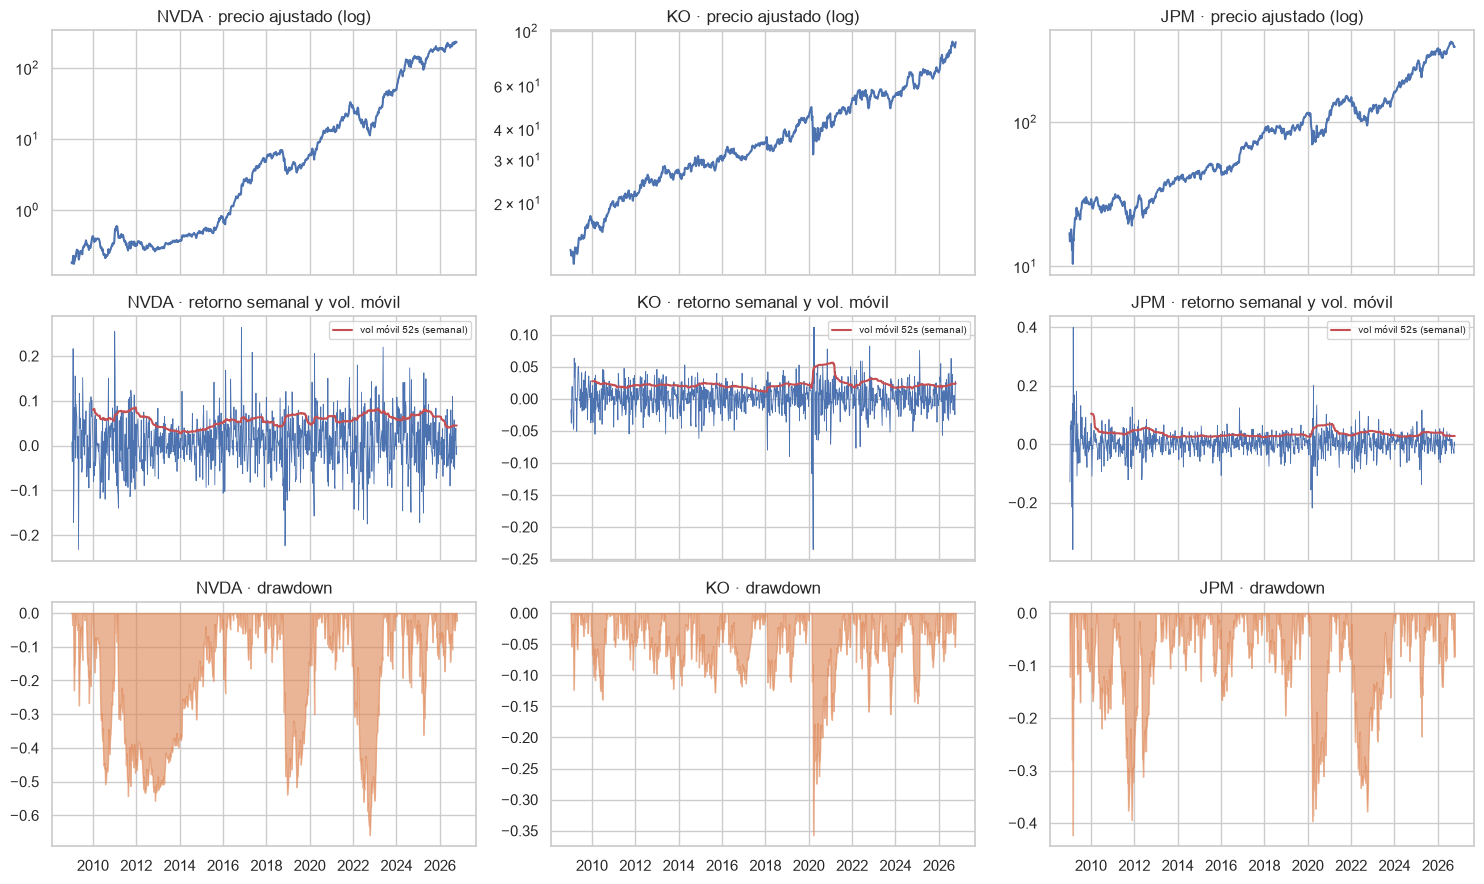

NVDA: peor drawdown -65.9% el 2022-10-10; vol anual media 43.4%; vol móvil máx 61.1%
KO: peor drawdown -35.7% el 2020-03-16; vol anual media 17.8%; vol móvil máx 40.6%
JPM: peor drawdown -42.3% el 2009-03-02; vol anual media 31.0%; vol móvil máx 75.2%


In [2]:
fig, ax = plt.subplots(3, 3, figsize=(15, 9), sharex=True)
dd_info = {}
for j, (ind_, t) in enumerate(REP.items()):
    mdd, dd = rg.max_drawdown(ancho[t].dropna())
    dd_info[t] = (mdd, dd.idxmin().date())
    ax[0, j].semilogy(ancho[t]); ax[0, j].set_title(f"{t} · precio ajustado (log)")
    ax[1, j].plot(R[t], lw=.6); ax[1, j].plot(rg.vol_historica(R[t]) / np.sqrt(52), c="C3", label="vol móvil 52s (semanal)")
    ax[1, j].set_title(f"{t} · retorno semanal y vol. móvil"); ax[1, j].legend(fontsize=7)
    ax[2, j].fill_between(dd.index, dd.values, 0, color="C1", alpha=.6); ax[2, j].set_title(f"{t} · drawdown")
fig.tight_layout(); fig.savefig(config.DIR_ASSETS / "eda_univariado_3tickers.png", dpi=150, bbox_inches="tight"); plt.show()
for t, (m, f) in dd_info.items():
    print(f"{t}: peor drawdown {m:.1%} el {f}; vol anual media {R[t].std()*np.sqrt(52):.1%}; vol móvil máx {rg.vol_historica(R[t]).max():.1%}")


**Lectura:** el peor drawdown fue -65.9% en NVDA (10-oct-2022), -35.7% en KO (16-mar-2020) y -42.3% en JPM (2-mar-2009); la volatilidad anual media es 43.4%, 17.8% y 31.0%, respectivamente. La volatilidad móvil de 52 semanas no es constante: llega a 61.1% (NVDA), 40.6% (KO) y 75.2% (JPM), es decir, entre 2.3 y 2.4 veces su media en KO y JPM. Esa variación en el tiempo (picos en 2009, 2020 y 2022) se asocia con la agrupación de volatilidad que se contrasta formalmente en las secciones 4 y 5.


## 2. Hechos estilizados: tabla para las 34 series (30 acciones + SPY, XLF, XLK, XLP)


In [3]:
hechos = pd.DataFrame({"media_anual": R.mean() * 52, "vol_anual": R.std() * np.sqrt(52),
                       "asimetria": R.skew(), "curtosis_exceso": R.kurt(),
                       "jb_p": R.apply(lambda s: stats.jarque_bera(s.dropna()).pvalue)})
print(hechos.describe().loc[["min", "25%", "50%", "75%", "max"]])
print("n por serie (mín-máx):", R.count().min(), R.count().max())
print("Series con JB p<0.05:", (hechos.jb_p < 0.05).sum(), "de", len(hechos), "| curtosis exceso>0:", (hechos.curtosis_exceso > 0).sum())
print("Asimetria<0 en", (hechos.asimetria < 0).sum(), "series")


     media_anual  vol_anual  asimetria  curtosis_exceso   jb_p
min      -0.0641     0.1312    -1.3696           1.4158 0.0000
25%       0.0840     0.1967    -0.6003           2.7895 0.0000
50%       0.1211     0.2777    -0.3150           4.6341 0.0000
75%       0.1627     0.3441     0.0779          10.3443 0.0000
max       0.4005     0.4570     0.3176          30.1601 0.0000
n por serie (mín-máx): 588 927
Series con JB p<0.05: 34 de 34 | curtosis exceso>0: 34
Asimetria<0 en 23 series


**Lectura:** la curtosis en exceso mediana es 4.63 (rango 1.42-30.16; una normal tendría 0) y es positiva en las 34 series; la asimetría mediana es -0.32 y es negativa en 23 de 34. La volatilidad anual mediana es 27.8% (rango 13.1%-45.7%). Jarque-Bera rechaza la normalidad (p<0.05) en 34 de 34 series, pero **con n entre 588 y 927 observaciones esta prueba casi siempre rechaza** incluso con desviaciones pequeñas y, además, supone observaciones independientes, lo cual no se cumple (sección 4). Por eso JB solo se reporta como descriptivo y la evidencia principal son los QQ-plots de la sección 3.

**Justificación:** se usan retornos logarítmicos semanales porque son aditivos en el tiempo y su frecuencia semanal atenúa el ruido de microestructura diario sin reducir demasiado n. La primera diferencia deja NaN al inicio de cada serie (META desde 2012, KHC desde 2015); no se imputa.


## 3. QQ-plots vs. normal y vs. t de Student


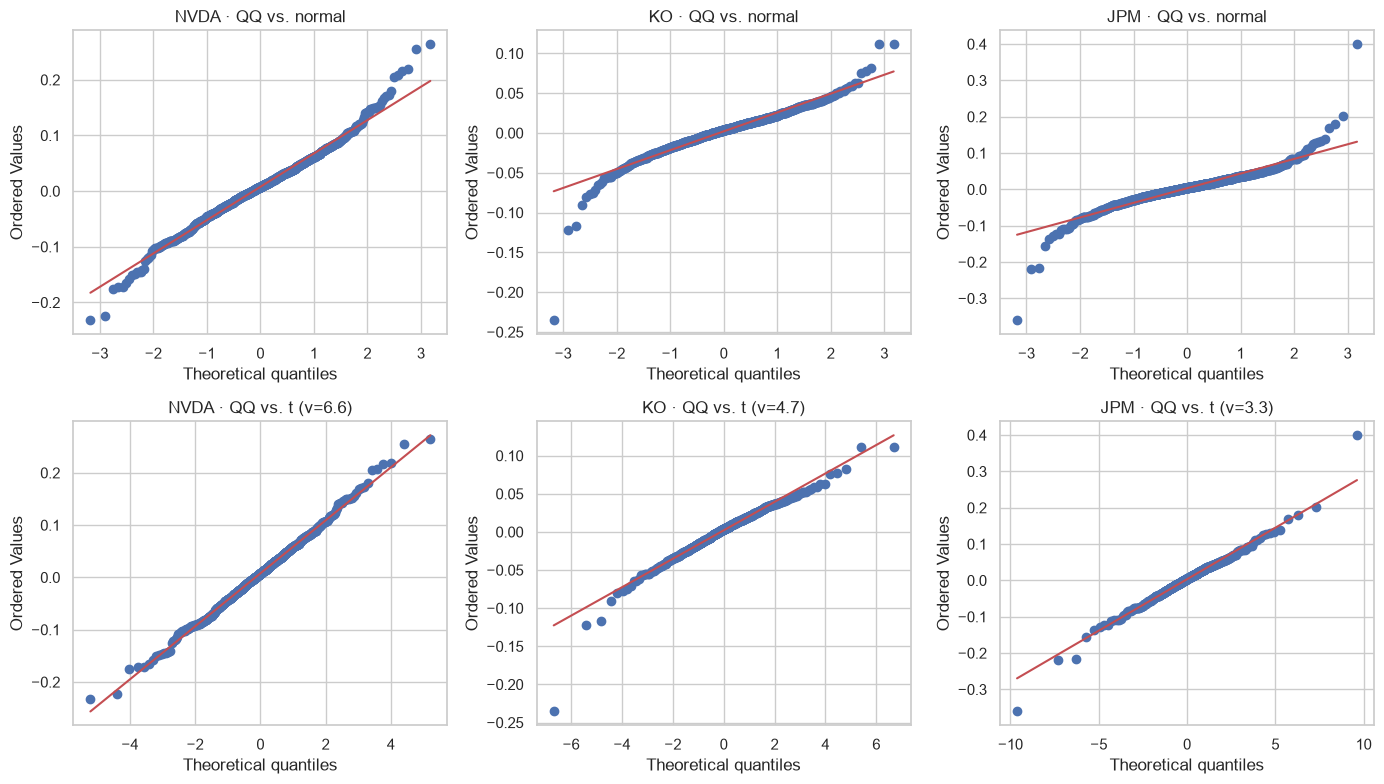

min   2.6988
25%   3.3112
50%   4.1458
75%   4.6845
max   6.5897
Name: nu, dtype: float64
Series con ν<10: 34 de 34 | ν<5: 27
{'NVDA': 6.59, 'KO': 4.65, 'JPM': 3.34}


In [4]:
t_fit = pd.DataFrame({t: dict(zip(["nu", "loc", "escala"], stats.t.fit(R[t].dropna()))) for t in R}).T
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for j, t in enumerate(REP.values()):
    x = R[t].dropna()
    stats.probplot(x, dist="norm", plot=ax[0, j]); ax[0, j].set_title(f"{t} · QQ vs. normal")
    nu = t_fit.loc[t, "nu"]
    stats.probplot(x, dist=stats.t, sparams=(nu,), plot=ax[1, j]); ax[1, j].set_title(f"{t} · QQ vs. t (ν={nu:.1f})")
fig.tight_layout(); fig.savefig(config.DIR_ASSETS / "qqplots_normal_vs_t.png", dpi=150, bbox_inches="tight"); plt.show()
print(t_fit["nu"].describe().loc[["min", "25%", "50%", "75%", "max"]])
print("Series con ν<10:", (t_fit.nu < 10).sum(), "de", len(t_fit), "| ν<5:", (t_fit.nu < 5).sum())
print(t_fit.loc[list(REP.values()), "nu"].round(2).to_dict())


**Lectura:** los grados de libertad ajustados tienen mediana 4.15 (rango 2.70-6.59) y son menores que 10 en las 34 series (27 con ν<5); NVDA 6.59, KO 4.65 y JPM 3.34. En los QQ-plots contra la normal los extremos se separan de la recta en ambas colas, mientras que contra la t con esos ν los puntos siguen la recta de forma mucho más cercana. Esto se asocia con colas pesadas; con ν cercano a 3 en JPM los momentos de orden 4 casi no existen, por lo que la curtosis muestral de la sección 2 es inestable. El ajuste de la t supone datos i.i.d.; se usa para describir la forma de las colas, no para inferencia.

**Justificación:** se ajusta la t de Student (3 parámetros) por máxima verosimilitud por ser la alternativa estándar de colas pesadas simétricas, y es la misma familia que se usa luego en GARCH-t.


## 4. HP0: dependencia temporal (autocorrelación en r y en r²)


{'LB_r_p': 0.5, 'LB_r2_p': 0.882, 'ARCH_LM_p': 0.853} | n series: 34
Tickers con LB(r) significativo: ['BAC', 'C', 'COST', 'JPM', 'KO', 'MDLZ', 'MS', 'ORCL', 'PG', 'PNC', 'SPY', 'TFC', 'USB', 'WFC', 'WMT', 'XLF', 'XLP']
Tickers SIN efecto ARCH: ['CSCO', 'GOOGL', 'KHC', 'SCHW', 'WMT']


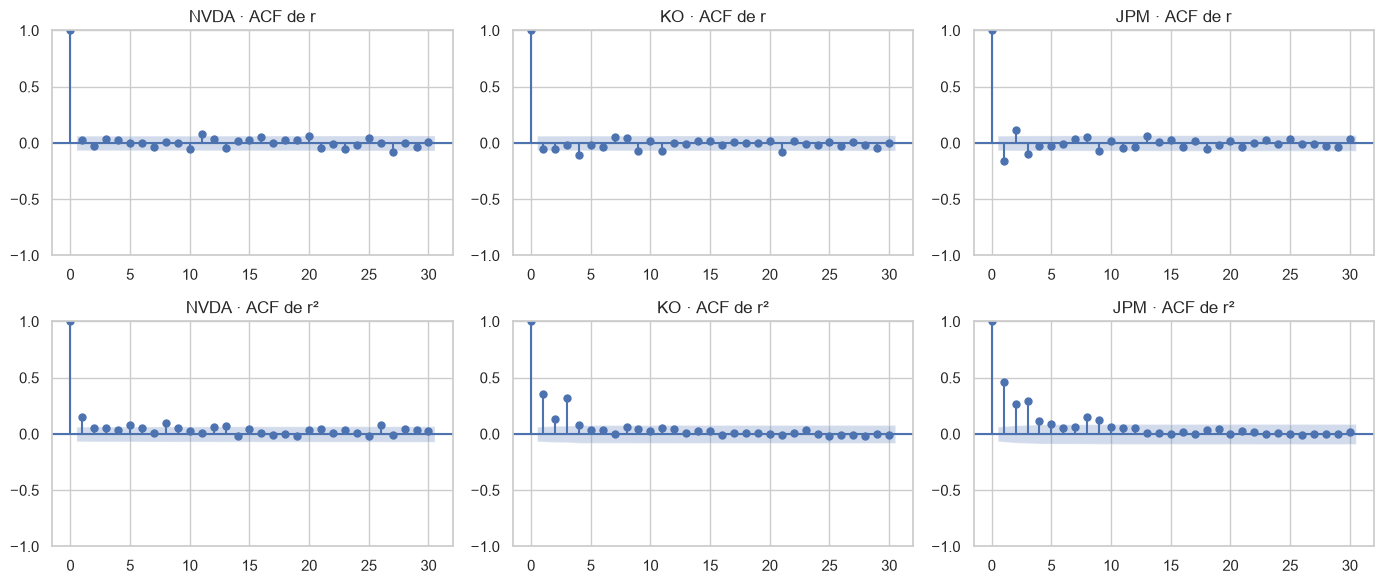

Tamaño del efecto: |rho1| mediana 0.068 (máx 0.218, USB) | |rho1|>0.1 en 6 de 34 | rho1<0 en 28
Representativos (rho1, p LB r, p LB r2): {'NVDA': (np.float64(0.025), np.float64(0.64), np.float64(0.0)), 'KO': (np.float64(-0.051), np.float64(0.003), np.float64(0.0)), 'JPM': (np.float64(-0.165), np.float64(0.0), np.float64(0.0))}
LB(r) significativo: 17 de los cuales financieros (8 bancos+XLF): 9 | falsos positivos esperados a 5% con 34 pruebas: 1.7


In [5]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf
dep = pd.DataFrame({t: {"LB_r_p": acorr_ljungbox(R[t].dropna(), lags=[10]).lb_pvalue.iloc[0],
                        "LB_r2_p": acorr_ljungbox(R[t].dropna() ** 2, lags=[10]).lb_pvalue.iloc[0],
                        "ARCH_LM_p": het_arch(R[t].dropna(), nlags=10)[1]} for t in R}).T
print((dep < 0.05).mean().round(3).to_dict(), "| n series:", len(dep))
print("Tickers con LB(r) significativo:", list(dep.index[dep.LB_r_p < 0.05]))
print("Tickers SIN efecto ARCH:", list(dep.index[dep.ARCH_LM_p >= 0.05]))
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for j, t in enumerate(REP.values()):
    x = R[t].dropna()
    plot_acf(x, lags=30, ax=ax[0, j], title=f"{t} · ACF de r"); plot_acf(x ** 2, lags=30, ax=ax[1, j], title=f"{t} · ACF de r²")
fig.tight_layout(); fig.savefig(config.DIR_ASSETS / "acf_r_r2.png", dpi=150, bbox_inches="tight"); plt.show()
rho1 = pd.Series({t: R[t].dropna().autocorr(1) for t in R})
print(f"Tamaño del efecto: |rho1| mediana {rho1.abs().median():.3f} (máx {rho1.abs().max():.3f}, {rho1.abs().idxmax()}) | |rho1|>0.1 en {(rho1.abs() > .1).sum()} de {len(rho1)} | rho1<0 en {(rho1 < 0).sum()}")
print("Representativos (rho1, p LB r, p LB r2):", {t: (round(rho1[t], 3), round(dep.loc[t, "LB_r_p"], 3), round(dep.loc[t, "LB_r2_p"], 4)) for t in REP.values()})
fin = [t for t in dep.index[dep.LB_r_p < .05] if t in config.UNIVERSO["financiero"] + ["XLF"]]
print("LB(r) significativo:", int((dep.LB_r_p < .05).sum()), "de los cuales financieros (8 bancos+XLF):", len(fin), "| falsos positivos esperados a 5% con 34 pruebas:", round(.05 * 34, 1))


**Lectura:** con Ljung-Box a 10 rezagos, la autocorrelación en r es significativa (p<0.05) en 50% de las series (17 de 34; 9 de ellas son financieras: 8 bancos y XLF), mientras que en r² lo es en 88.2% y el test ARCH-LM rechaza homocedasticidad en 85.3%; solo CSCO, GOOGL, KHC, SCHW y WMT no muestran efecto ARCH. El patrón de Cont (2001), poca autocorrelación en r y mucha en r², se cumple en dirección pero **no de forma limpia**: la autocorrelación en r es mayor a la esperada (la dependencia en r² y las colas pesadas distorsionan el nivel de la prueba, y los episodios de 2009 y 2020 pesan mucho). El tamaño del efecto es pequeño: |ρ₁| mediana 0.068 (máximo 0.218 en USB), mayor que 0.1 en solo 6 de 34 series y ρ₁<0 en 28 de 34. Para los tres representativos, ρ₁ = 0.025 en NVDA (LB p=0.64: la ACF de r no sale de la banda), -0.051 en KO (LB p=0.003) y -0.165 en JPM (LB p<0.001): en KO y JPM sí hay dependencia lineal en r, aunque en KO es modesta; en los tres, LB sobre r² da p<0.001 y la ACF de r² es persistente. Con 34 pruebas al 5% se esperarían ~1.7 falsos positivos, así que 17 no se explican por multiplicidad. En la sección 5b se revisa si esta dependencia sobrevive a la modelación de la volatilidad. Asociación, no causalidad: las pruebas suponen una estructura lineal y no prueban un mecanismo.

**Justificación:** se usa un solo rezago (10 semanas, ~2.5 meses) para evitar mucha multiplicidad de pruebas; 34 series x 3 pruebas implica falsos positivos esperados (~5%), pequeños frente a 88%.


## 5. Volatilidad EWMA y GARCH(1,1)-t con corte temporal (sin look-ahead)

**Justificación:** el modelo se estima con datos hasta 2019-12-31 y se evalúa fuera de muestra después de esa fecha, filtrando con los parámetros fijos (la volatilidad de cada semana usa solo información anterior). Los retornos se escalan x100 para que el optimizador de `arch` converja bien. Se compara contra EWMA (λ=0.94), la volatilidad histórica de 52 semanas y la volatilidad constante del GBM estimada en la muestra de entrenamiento, con la pérdida QLIKE = media(ln h + r²/h) (menor es mejor), robusta frente al ruido de r² como proxy de la varianza.


In [6]:
from arch import arch_model
CORTE = pd.Timestamp("2019-12-31")
filas, ql, AJ, VOLG = {}, {}, {}, {}
for t in R:
    r = R[t].dropna() * 100
    tr, te = r[r.index <= CORTE], r[r.index > CORTE]
    am = arch_model(tr, vol="GARCH", p=1, q=1, dist="t", mean="Constant")
    res = am.fit(disp="off", show_warning=False)
    p = res.params
    vg = arch_model(r, vol="GARCH", p=1, q=1, dist="t").fix(p).conditional_volatility
    AJ[t] = p; VOLG[t] = vg; h_g = vg[te.index] ** 2
    h_e = ((rg.vol_ewma(r, 0.94, 1).shift(1)) ** 2)[te.index]
    h_h = ((r.rolling(52).std(ddof=1)).shift(1) ** 2)[te.index]
    h_c = pd.Series(tr.var(ddof=1), index=te.index)
    q = lambda h: float((np.log(h) + (te - 0) ** 2 / h).mean())
    filas[t] = {"alpha": p["alpha[1]"], "beta": p["beta[1]"], "persistencia": p["alpha[1]"] + p["beta[1]"], "nu": p["nu"],
                "convergio": res.convergence_flag == 0, "n_train": len(tr)}
    ql[t] = {"GARCH-t": q(h_g), "EWMA": q(h_e), "Hist52": q(h_h), "GBM_const": q(h_c)}
garch = pd.DataFrame(filas).T; qlike = pd.DataFrame(ql).T
garch = garch.astype({"convergio": bool, "n_train": int}).astype({c: float for c in ["alpha", "beta", "persistencia", "nu"]})
print(garch[["alpha", "beta", "persistencia", "nu"]].describe().loc[["min", "50%", "max"]])
print("No convergieron:", list(garch.index[~garch.convergio]), "| persistencia>=1:", list(garch.index[garch.persistencia >= 1]))
print("QLIKE medio fuera de muestra (mediana entre series):\n", qlike.median().round(4).to_dict())
print("Series donde GARCH-t < GBM const:", int((qlike["GARCH-t"] < qlike["GBM_const"]).sum()), "| < EWMA:", int((qlike["GARCH-t"] < qlike["EWMA"]).sum()), "| < Hist52:", int((qlike["GARCH-t"] < qlike["Hist52"]).sum()), "de", len(qlike))
print("Esquina alpha~0 (<1e-4):", list(garch.index[garch.alpha < 1e-4]), "| persistencia<0.5:", {t: round(v, 3) for t, v in garch.persistencia[garch.persistencia < .5].items()})


     alpha   beta  persistencia      nu
min 0.0000 0.0860        0.2803  3.8299
50% 0.0564 0.8734        0.9427  7.7100
max 0.2716 0.9903        0.9903 13.8253
No convergieron: [] | persistencia>=1: []
QLIKE medio fuera de muestra (mediana entre series):
 {'GARCH-t': 3.7126, 'EWMA': 3.798, 'Hist52': 3.8724, 'GBM_const': 3.8832}
Series donde GARCH-t < GBM const: 28 | < EWMA: 23 | < Hist52: 28 de 34
Esquina alpha~0 (<1e-4): ['ADBE', 'CSCO'] | persistencia<0.5: {'KO': 0.28}


       alpha   beta  persistencia      nu  n_train
AAPL  0.0770 0.8490        0.9260  8.8290      573
ADBE  0.0000 0.9840        0.9840  5.3300      573
BAC   0.0730 0.8660        0.9390  7.6950      573
C     0.1190 0.8240        0.9430 13.8250      573
CL    0.0450 0.8790        0.9240  8.3800      573
COST  0.0330 0.9120        0.9460  8.5080      573
CRM   0.0470 0.9380        0.9860  8.1410      573
CSCO  0.0000 0.9900        0.9900  4.6020      573
GIS   0.0320 0.9400        0.9730  5.4050      573
GOOGL 0.0300 0.8970        0.9270  5.6100      573
GS    0.1140 0.8060        0.9200 10.0410      573
INTC  0.0440 0.9080        0.9510  8.2020      573
JPM   0.0840 0.8430        0.9270  7.0540      573
KHC   0.0180 0.9470        0.9650  3.8300      234
KMB   0.0510 0.9240        0.9740  6.7540      573
KO    0.1940 0.0860        0.2800 11.2790      573
MDLZ  0.0240 0.9390        0.9640  6.7630      573
META  0.0310 0.9500        0.9810  4.4590      398
MS    0.1370 0.8020        0.93

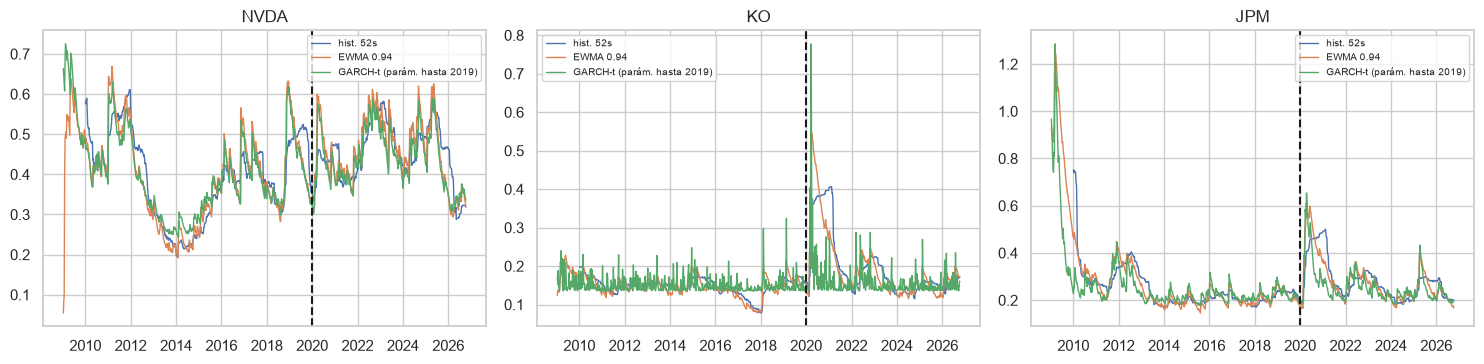

NVDA: vol anual fuera de muestra GARCH-t máx 59.0% (2025-04-21), mediana 43.1% | EWMA máx 62.6% | hist52 máx 58.3% | corr(GARCH,EWMA) 0.96
KO: vol anual fuera de muestra GARCH-t máx 77.7% (2020-03-23), mediana 14.5% | EWMA máx 54.4% | hist52 máx 40.6% | corr(GARCH,EWMA) 0.50
JPM: vol anual fuera de muestra GARCH-t máx 65.4% (2020-04-13), mediana 23.7% | EWMA máx 61.0% | hist52 máx 50.0% | corr(GARCH,EWMA) 0.89


In [7]:
print(garch[["alpha", "beta", "persistencia", "nu", "n_train"]].round(3).to_string())
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
for j, t in enumerate(REP.values()):
    g = VOLG[t] * np.sqrt(52) / 100
    ax[j].plot(rg.vol_historica(R[t]), label="hist. 52s", lw=1); ax[j].plot(rg.vol_ewma(R[t]), label="EWMA 0.94", lw=1)
    ax[j].plot(g, label="GARCH-t (parám. hasta 2019)", lw=1); ax[j].axvline(CORTE, c="k", ls="--"); ax[j].set_title(t); ax[j].legend(fontsize=7)
fig.tight_layout(); fig.savefig(config.DIR_ASSETS / "vol_ewma_garch.png", dpi=150, bbox_inches="tight"); plt.show()
o = lambda x: x[x.index > CORTE]
for t in REP.values():
    g = VOLG[t] * np.sqrt(52) / 100; e, h = rg.vol_ewma(R[t]), rg.vol_historica(R[t])
    print(f"{t}: vol anual fuera de muestra GARCH-t máx {o(g).max():.1%} ({o(g).idxmax().date()}), mediana {o(g).median():.1%} | EWMA máx {o(e).max():.1%} | hist52 máx {o(h).max():.1%} | corr(GARCH,EWMA) {o(g).corr(o(e)):.2f}")


### 5b. Robustez de la dependencia lineal en r (HT0): residuos estandarizados de GARCH-t


In [8]:
# Robustez de HT0: Ljung-Box sobre residuos estandarizados de GARCH-t y sobre r sin los episodios 2009 y 2020
rob = {}
for t in R:
    r = R[t].dropna() * 100; mu = AJ[t]["mu"]
    z = ((r - mu) / VOLG[t]).dropna()
    z_tr = z[z.index <= CORTE]
    excl = R[t].dropna()[~((R[t].dropna().index.year == 2009) | (R[t].dropna().index.year == 2020))]
    rob[t] = {"LB_z_p": acorr_ljungbox(z, lags=[10]).lb_pvalue.iloc[0], "LB_z_train_p": acorr_ljungbox(z_tr, lags=[10]).lb_pvalue.iloc[0],
              "LB_r_sin_crisis_p": acorr_ljungbox(excl, lags=[10]).lb_pvalue.iloc[0], "LB_z2_p": acorr_ljungbox(z ** 2, lags=[10]).lb_pvalue.iloc[0]}
rob = pd.DataFrame(rob).T
print("% significativos (p<0.05):", (rob < .05).mean().round(3).to_dict())
print("LB(r) original:", round((dep.LB_r_p < .05).mean(), 3), "| LB(r) sin 2009 y 2020 significativos en", int((rob.LB_r_sin_crisis_p < .05).sum()), "de 34")
print("Bonferroni (p<0.05/34) LB(r) original:", int((dep.LB_r_p < .05 / 34).sum()), "| LB(z) :", int((rob.LB_z_p < .05 / 34).sum()))


% significativos (p<0.05): {'LB_z_p': 0.118, 'LB_z_train_p': 0.088, 'LB_r_sin_crisis_p': 0.265, 'LB_z2_p': 0.147}
LB(r) original: 0.5 | LB(r) sin 2009 y 2020 significativos en 9 de 34
Bonferroni (p<0.05/34) LB(r) original: 7 | LB(z) : 1


**Robustez de HT0 (sección 5b).** Resultados de la celda anterior: la prueba de Ljung-Box (10 rezagos) sobre los residuos estandarizados de GARCH-t es significativa en 11.8% de las series (4 de 34; 8.8% si se usa solo la muestra de entrenamiento hasta 2019), frente a 50% sobre r; sobre r excluyendo 2009 y 2020 baja a 26.5% (9 de 34). Con corrección de Bonferroni (p<0.0015) quedan 7 series sobre r y solo 1 sobre los residuos estandarizados. Es decir, buena parte de la "autocorrelación" de r se asocia con la volatilidad cambiante (los episodios extremos de 2009 y 2020 y su mal modelado por una prueba que supone varianza constante); tras modelarla, la dependencia lineal remanente es cercana al nivel nominal de 5% (aunque algo mayor) y su tamaño es pequeño (|ρ₁| mediana 0.068).

**Otras explicaciones posibles** de la dependencia lineal remanente (no se prueban aquí): (i) negociación no sincrónica o poca liquidez, poco probable en acciones de alta capitalización y datos semanales, pero posible en los ETF y bancos; (ii) rebote bid-ask, coherente con ρ₁<0 en 28 de 34 series, aunque el efecto semanal es pequeño; (iii) media condicional que varía en el tiempo (primas de riesgo, regímenes), que una prueba de ρ constante promedia; (iv) multiplicidad: 34 pruebas al 5% generan ~1.7 rechazos por azar, y las series están correlacionadas entre sí (bancos, ETF), por lo que los rechazos no son independientes. Además, ADF y KPSS contrastan raíces unitarias en los niveles, no la predecibilidad direccional: que no se rechace la raíz unitaria es consistente con una caminata aleatoria, pero no la demuestra ni descarta una pequeña predecibilidad en dirección.

**Estado de HT0: apoyada, con dependencia lineal pequeña pero no nula.** La caminata aleatoria sigue siendo la línea base razonable para el SVM (ADF 33 de 34; |ρ₁| mediana 0.068; Ljung-Box sobre residuos estandarizados 11.8%); el margen que el SVM debe superar es una dirección casi impredecible, y cualquier ganancia pequeña debe validarse fuera de muestra.


**Lectura:** la persistencia α+β mediana es 0.943 (rango 0.280-0.990) y ninguna serie alcanza 1; el ν de la t condicional tiene mediana 7.71 (rango 3.83-13.83), mayor que el ν incondicional de la sección 3 (mediana 4.15) porque parte del exceso de curtosis lo explica ya la volatilidad cambiante. Los 34 ajustes convergieron. Fuera de muestra (desde 2020), la pérdida QLIKE mediana es 3.713 para GARCH-t, 3.798 para EWMA, 3.872 para la histórica de 52 semanas y 3.883 para la volatilidad constante del GBM; GARCH-t es mejor que el GBM en 28 de 34 series, que EWMA en 23 y que la histórica en 28. Las diferencias son moderadas y vienen de un único periodo fuera de muestra (con el choque de 2020), por lo que se leen como asociación y no como superioridad definitiva.

**Figura (vol. anual fuera de muestra, desde 2020):** en NVDA la volatilidad GARCH-t llega a un máximo de 59.0% (21-abr-2025), con EWMA 62.6% e histórica de 52 semanas 58.3%, y corr(GARCH, EWMA)=0.96; en JPM 65.4% (13-abr-2020) vs. 61.0% y 50.0% (corr 0.89); en KO el GARCH-t sube a 77.7% (23-mar-2020) frente a 54.4% (EWMA) y 40.6% (histórica) con corr 0.50. La histórica de 52 semanas reacciona tarde y cae lentamente tras el choque, mientras GARCH-t y EWMA responden en la misma semana.

**Casos atípicos de la tabla:** KO tiene la persistencia más baja (0.280): con α+β tan bajo la volatilidad vuelve casi de inmediato a su nivel de largo plazo y el ajuste hasta 2019 casi no captó el agrupamiento, lo que explica el pico exagerado de 77.7% en marzo de 2020 y la baja correlación con EWMA. ADBE y CSCO caen en la esquina α≈0 (<1e-4), una solución de frontera: el optimizador no encuentra efecto ARCH en la muestra de entrenamiento (coherente con CSCO sin efecto ARCH en la sección 4) y su σ_t queda casi constante; sus resultados GARCH se leen con cautela.

**Justificación:** se descarta el GBM de volatilidad constante como modelo de simulación por defecto y se adopta una volatilidad condicional con colas t. Se mantiene EWMA como alternativa simple (más barata y casi igual de buena en 23 de 34 series).


**Síntesis (sección 1-5, HP0).**
- Hecho estilizado de colas: curtosis en exceso mediana 4.63 y ν mediano 4.15 (<10 en 34 de 34): colas pesadas.
- Agrupación de volatilidad: LB en r² significativo en 88.2% de las series y ARCH-LM en 85.3%, frente a 50% en r (patrón de Cont solo parcial).
- GARCH(1,1)-t con persistencia mediana 0.943 supera al GBM de volatilidad constante en 28 de 34 series fuera de muestra (QLIKE 3.713 vs. 3.883).
- **HP0: apoyada** (el GBM normal con volatilidad constante no es adecuado; se pasa a GARCH-t, con EWMA como alternativa simple). **HT4: apoyada** (ARCH-LM y LB(r²) significativos en 85-88% de las series; persistencia mediana 0.943). Salvedad: la ventaja fuera de muestra es moderada y la autocorrelación en r no es tan baja como se esperaba.
- **Decisiones que alimenta:** la simulación usa volatilidad condicional con innovaciones t (no GBM normal); las barreras de la etiqueta se escalan con σ (HT4).


## 6. HT0: estacionariedad (ADF y KPSS)


In [9]:
from statsmodels.tsa.stattools import adfuller, kpss
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # KPSS trunca p a [0.01, 0.10]; se documenta en la lectura
    est = pd.DataFrame({t: {"ADF_logp_p": adfuller(np.log(ancho[t].dropna()))[1],
                        "KPSS_logp_p": kpss(np.log(ancho[t].dropna()), nlags="auto")[1],
                        "ADF_r_p": adfuller(R[t].dropna())[1]} for t in ancho}).T
n = len(est)
print("ADF log-precio NO rechaza raíz unitaria (p>=0.05):", (est.ADF_logp_p >= .05).sum(), "de", n)
print("KPSS log-precio rechaza estacionariedad (p<0.05):", (est.KPSS_logp_p < .05).sum(), "| p truncado en 0.01:", (est.KPSS_logp_p <= 0.0101).sum(), "| en 0.10:", (est.KPSS_logp_p >= 0.0999).sum())
print("ADF retornos rechaza raíz unitaria (p<0.05):", (est.ADF_r_p < .05).sum(), "de", n)
conj = (est.ADF_logp_p >= .05) & (est.ADF_r_p < .05)
print("Conjunto (no se rechaza en log-precio y sí en r):", conj.sum(), "de", n, f"= {conj.mean():.1%}")
print("Excepciones a la raíz unitaria en log-precio:", list(est.index[est.ADF_logp_p < .05]))


ADF log-precio NO rechaza raíz unitaria (p>=0.05): 33 de 34
KPSS log-precio rechaza estacionariedad (p<0.05): 34 | p truncado en 0.01: 34 | en 0.10: 0
ADF retornos rechaza raíz unitaria (p<0.05): 34 de 34
Conjunto (no se rechaza en log-precio y sí en r): 33 de 34 = 97.1%
Excepciones a la raíz unitaria en log-precio: ['CRM']


In [10]:
filas = []
for t in config.tickers():
    ti = ind.tabla_indicadores(ancho[t].dropna(), vol_ancho[t].reindex(ancho[t].dropna().index)).dropna()
    for c in ti: filas.append((t, c, adfuller(ti[c])[1]))
adf_ind = pd.DataFrame(filas, columns=["ticker", "indicador", "p"]).pivot(index="ticker", columns="indicador", values="p")
res_ind = pd.DataFrame({"pct_estacionario": (adf_ind < .05).mean(), "p_mediana": adf_ind.median(), "p_max": adf_ind.max()})
print(res_ind.round(4))
print("Pares ticker-indicador estacionarios:", int((adf_ind < .05).sum().sum()), "de", adf_ind.size)
print("No estacionarios (p>=0.05):", {c: list(adf_ind.index[adf_ind[c] >= .05]) for c in adf_ind if (adf_ind[c] >= .05).any()})


            pct_estacionario  p_mediana  p_max
indicador                                     
dist_ema20            1.0000     0.0000 0.0001
dist_sma20            1.0000     0.0000 0.0003
dist_sma50            1.0000     0.0003 0.0172
donchian20            1.0000     0.0000 0.0000
mom_12_1              0.9333     0.0028 0.9598
rsi14                 1.0000     0.0000 0.0001
vol_rel20             1.0000     0.0000 0.0000
Pares ticker-indicador estacionarios: 208 de 210
No estacionarios (p>=0.05): {'mom_12_1': ['INTC', 'KHC']}


**Lectura:** ADF no rechaza la raíz unitaria en el log-precio en 33 de 34 series (la excepción es CRM) y la rechaza en los retornos en 34 de 34; el patrón conjunto (no estacionario en nivel, estacionario en retorno) aparece en 33 de 34 series (97.1%). KPSS confirma el resultado con signo contrario: rechaza la estacionariedad del log-precio en 34 de 34, pero **el valor p está truncado en 0.01 en las 34** (la tabla de statsmodels no llega más abajo y emite `InterpolationWarning`), así que solo se lee como "p ≤ 0.01", no como magnitud. Sobre los 7 indicadores técnicos en las 30 acciones, ADF rechaza la raíz unitaria en 208 de 210 pares; las únicas excepciones son `mom_12_1` en INTC y KHC (los 6 indicadores restantes son estacionarios en 30 de 30 y `mom_12_1` en 28 de 30). Que el ADF no rechace no prueba la raíz unitaria (baja potencia); la convergencia con KPSS en sentido opuesto es lo que da respaldo.

**Justificación:** la línea base de predicción para el SVM es la caminata aleatoria (el último retorno o la dirección más frecuente), no un modelo del nivel del precio. Los indicadores se usan como variables porque son estacionarios; `mom_12_1` se mantiene pero con la salvedad de INTC y KHC (muestra corta o cambio de régimen).

**Síntesis (sección 6, HT0): apoyada, con dependencia lineal pequeña.** 33 de 34 log-precios con raíz unitaria no rechazada y retornos estacionarios en 34 de 34; indicadores estacionarios en 208 de 210 pares. Ljung-Box sobre r es significativo en 50% de las series (sección 4), pero baja a 11.8% con residuos estandarizados de GARCH-t y el efecto es pequeño (|ρ₁| mediana 0.068; sección 5b). ADF/KPSS contrastan raíces unitarias en niveles, no predecibilidad direccional. Decisión: la caminata aleatoria es el rival a batir por el SVM, y se predice con retornos/indicadores, no con niveles.


## 7. Descomposición STL del precio mensual (período 12)


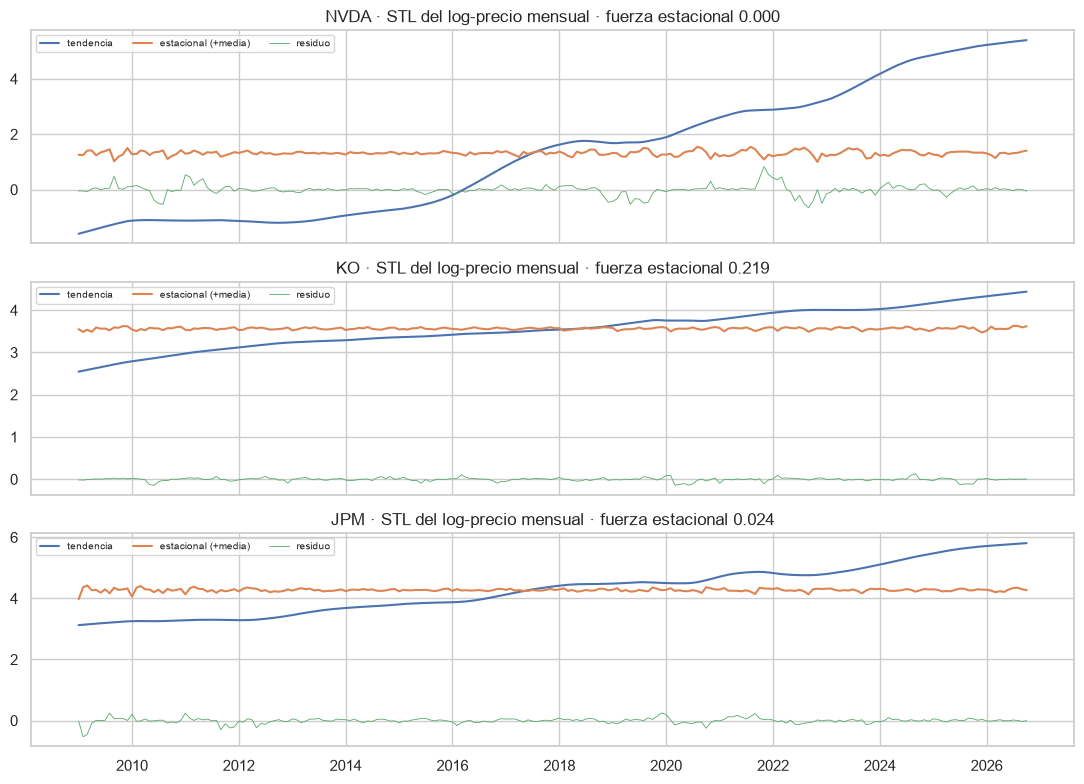

{'NVDA': 0.0, 'KO': 0.219, 'JPM': 0.024}
Fuerza estacional (30 acciones): mediana 0.058 máx 0.336 KMB | >0.3: 2


In [11]:
from statsmodels.tsa.seasonal import STL
mens = datos.a_ancho(datos.cargar_snapshot("precios_mensuales"))
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True); fuerza = {}
for k, t in enumerate(REP.values()):
    s = np.log(mens[t].dropna()); s.index = pd.DatetimeIndex(s.index).to_period("M").to_timestamp()
    d = STL(s, period=12, robust=True).fit()
    fuerza[t] = max(0, 1 - d.resid.var() / (d.seasonal + d.resid).var())
    ax[k].plot(d.trend, label="tendencia"); ax[k].plot(d.seasonal + d.trend.mean(), label="estacional (+media)"); ax[k].plot(d.resid, label="residuo", lw=.6)
    ax[k].set_title(f"{t} · STL del log-precio mensual · fuerza estacional {fuerza[t]:.3f}"); ax[k].legend(fontsize=7, ncol=3)
fig.tight_layout(); fig.savefig(config.DIR_ASSETS / "stl_mensual.png", dpi=150, bbox_inches="tight"); plt.show()
f_all = {}
for t in config.tickers():
    s = np.log(mens[t].dropna()); d = STL(s, period=12, robust=True).fit()
    f_all[t] = max(0, 1 - d.resid.var() / (d.seasonal + d.resid).var())
f_all = pd.Series(f_all); print(pd.Series(fuerza).round(3).to_dict()); print("Fuerza estacional (30 acciones): mediana", round(f_all.median(), 3), "máx", round(f_all.max(), 3), f_all.idxmax(), "| >0.3:", int((f_all > .3).sum()))


**Lectura:** la fuerza estacional (1 - var(resid)/var(estacional+resid)) es 0.000 en NVDA, 0.219 en KO y 0.024 en JPM; entre las 30 acciones la mediana es 0.058 (máximo 0.336 en KMB, y solo 2 acciones superan 0.30). La estacionalidad anual es entonces baja en la mayoría de las series; KO muestra un componente débil-moderado que, al estimarse con apenas ~17 ciclos anuales, no se interpreta como regularidad explotable. Con la mayor parte de la variación en tendencia y residuo, **no se identifica estacionalidad relevante** y no se incluyen variables de mes del año en el modelo base.

**Justificación:** se descompone el log-precio mensual (no el semanal) porque 12 meses es un período entero natural; STL robusto reduce la influencia de 2009 y 2020.

## 8. HF1: múltiplos frente a su historia
**Justificación:** los no financieros se analizan con P/E y los financieros con P/B, porque el P/E de un banco depende de reservas y apalancamiento y el valor en libros es la ancla habitual. `multiplos_semanales` alinea cada ratio con la fecha de publicación (`filed`) para evitar look-ahead; EPS ≤ 0 deja el múltiplo en NaN (no se imputa). GOOGL carece de acciones en EDGAR, por lo que no tiene P/E y se reporta como NaN.


In [12]:
rat = datos.cargar_snapshot("ratios_anuales")
mult, pctl = {}, {}
for t in config.tickers():
    pr = ancho[t].dropna().rename("close").rename_axis("fecha").reset_index()
    m = fu.multiplos_semanales(pr, rat[rat.ticker == t]).set_index("fecha")
    col = "pb" if t in config.UNIVERSO["financiero"] else "pe"
    mult[t] = m[col]; pctl[t] = fu.percentil_expansivo(m[col])
MULT = pd.DataFrame(mult); PCT = pd.DataFrame(pctl)
print("Columna usada: P/B financieros, P/E el resto | cobertura no-NaN (mediana):", round(MULT.notna().mean().median(), 3))
print("Sin múltiplo (cobertura<20%):", list(MULT.columns[MULT.notna().mean() < .2]))
print(MULT.describe().T[["count", "min", "50%", "max"]].round(2).sort_values("max").tail(4))


Columna usada: P/B financieros, P/E el resto | cobertura no-NaN (mediana): 0.914
Sin múltiplo (cobertura<20%): ['GOOGL']
        count     min     50%       max
INTC 831.0000  5.0400 12.4000  117.1100
ADBE 873.0000 11.6900 48.2700  178.6500
CRM  553.0000 19.4200 76.6600 1794.5900
META 715.0000  8.9100 34.8100 2532.8500


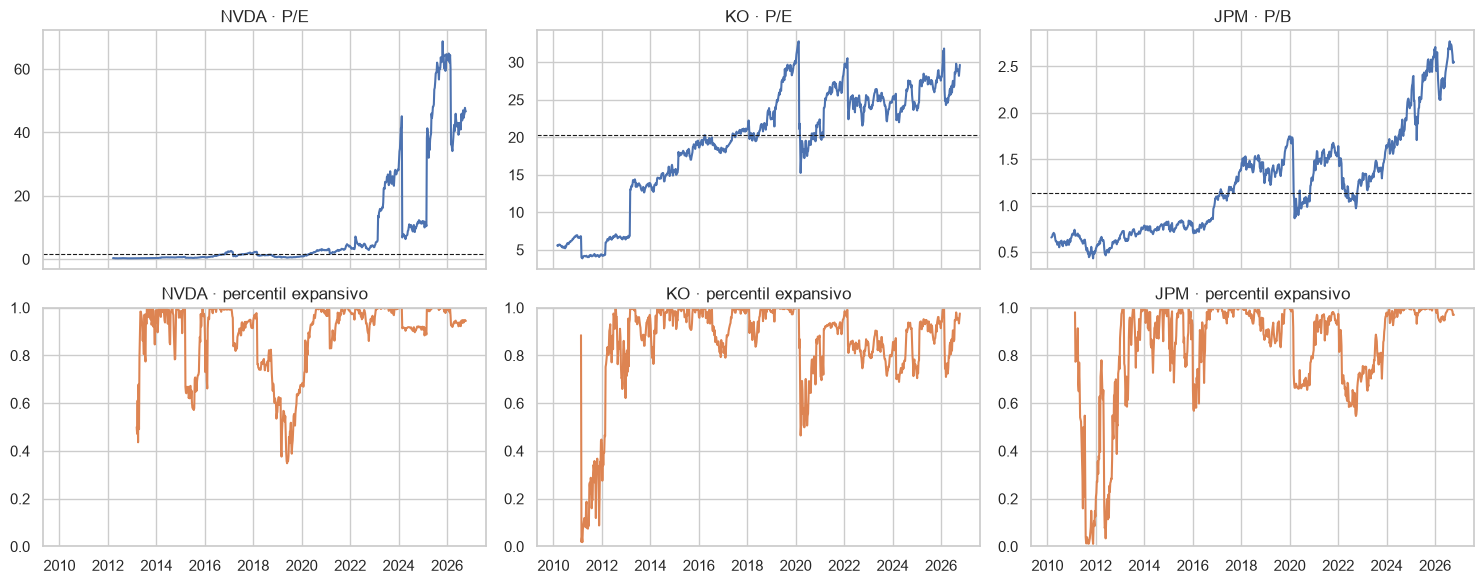

             n  ADF_p        m    eta  vida_media_anios  vida_media_log  pct_actual  revierte
AAPL  885.0000 0.8730  42.4810 0.0910            7.6230         11.0360      0.9990     False
MSFT  846.0000 0.2050  31.3410 0.5240            1.3220          2.2130      0.4460     False
GOOGL  88.0000    NaN      NaN    NaN               NaN             NaN         NaN     False
META  715.0000 0.0160 104.1150 1.6050            0.4320          0.9500      0.4170      True
NVDA  761.0000 0.7000  20.2170 0.2860            2.4280          9.3490      0.9450     False
ORCL  850.0000 0.4310  23.6270 0.6300            1.1000          1.3350      0.7320     False
ADBE  873.0000 0.2800  54.0370 0.5210            1.3300          2.3500      0.0110     False
CRM   553.0000 0.0920 334.8290 1.2850            0.5390          0.6460      0.0690     False
CSCO  838.0000 0.9780  27.0210 0.1340            5.1570          3.8920      0.9750     False
INTC  831.0000 0.9530  56.8590 0.1610            4.2980     

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
for j, t in enumerate(REP.values()):
    ax[0, j].plot(MULT[t]); ax[0, j].set_title(f"{t} · {'P/B' if t=='JPM' else 'P/E'}")
    ax[0, j].axhline(MULT[t].median(), c="k", ls="--", lw=.8)
    ax[1, j].plot(PCT[t], c="C1"); ax[1, j].set_ylim(0, 1); ax[1, j].set_title(f"{t} · percentil expansivo")
fig.tight_layout(); fig.savefig(config.DIR_ASSETS / "multiplos_percentil.png", dpi=150, bbox_inches="tight"); plt.show()
filas = {}
for t in MULT:
    x = MULT[t].dropna()
    if len(x) < 150: filas[t] = {"n": len(x)}; continue
    ou = rg.ajuste_ou(x); ou_l = rg.ajuste_ou(np.log(x.where(x > 0)).dropna())
    filas[t] = {"n": len(x), "ADF_p": adfuller(x)[1], "m": ou["m"], "eta": ou["eta"], "vida_media_anios": ou["vida_media_anios"],
                "vida_media_log": ou_l["vida_media_anios"], "pct_actual": PCT[t].dropna().iloc[-1]}
hf1 = pd.DataFrame(filas).T.astype(float)
hf1["revierte"] = hf1.eta.notna() & (hf1.ADF_p < .05)
print(hf1.round(3).to_string())
for t in REP.values():
    x = MULT[t].dropna(); print(f"{t}: múltiplo mediana {x.median():.2f}, mín {x.min():.2f}, máx {x.max():.2f}, actual {x.iloc[-1]:.2f}, percentil expansivo actual {PCT[t].dropna().iloc[-1]:.3f} (mín {PCT[t].min():.3f})")


In [14]:
v = hf1.dropna(subset=["ADF_p"]); rev = v[v.revierte]
print("Tickers evaluables:", len(v), "| ADF p<0.05:", int((v.ADF_p < .05).sum()), "| eta finito:", int(v.eta.notna().sum()), "| revierten (ambos):", len(rev))
print("Vida media (años) entre los que revierten: mediana", round(rev.vida_media_anios.median(), 2), "rango", round(rev.vida_media_anios.min(), 2), "-", round(rev.vida_media_anios.max(), 2))
print("Con el log-múltiplo: vida media mediana", round(v.vida_media_log.median(), 2), "| con eta finito", int(v.vida_media_log.notna().sum()), "| sin reversión:", list(v.index[v.eta.isna()]))
print("Revierten por industria:", {i: int(v.loc[v.index.isin(l), "revierte"].sum()) for i, l in config.UNIVERSO.items()})
print("No revierten:", list(v.index[~v.revierte]))
print("Revierten:", {t: round(float(rev.loc[t, "vida_media_anios"]), 2) for t in rev.index}); print("Vida media (eta finito, todos): mediana", round(v.vida_media_anios.median(), 2), "| ADF p mediana", round(v.ADF_p.median(), 3))


Tickers evaluables: 29 | ADF p<0.05: 4 | eta finito: 28 | revierten (ambos): 4
Vida media (años) entre los que revierten: mediana 0.48 rango 0.43 - 0.58
Con el log-múltiplo: vida media mediana 1.54 | con eta finito 29 | sin reversión: ['MS']
Revierten por industria: {'tecnologia': 1, 'consumo_defensivo': 0, 'financiero': 3}
No revierten: ['AAPL', 'MSFT', 'NVDA', 'ORCL', 'ADBE', 'CRM', 'CSCO', 'INTC', 'KO', 'PEP', 'PG', 'WMT', 'COST', 'CL', 'MDLZ', 'KMB', 'GIS', 'KHC', 'JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'PNC']
Revierten: {'META': 0.43, 'USB': 0.49, 'TFC': 0.48, 'SCHW': 0.58}
Vida media (eta finito, todos): mediana 1.31 | ADF p mediana 0.355


In [15]:
# Diagnóstico: EPS de EDGAR "as-filed" (sin ajustar por splits) frente a precios ajustados por splits
nf = [t for t in MULT if t not in config.UNIVERSO["financiero"]]
bajo = pd.Series({t: (MULT[t].dropna() < 5).mean() for t in nf}).sort_values(ascending=False)
print("Fracción de semanas con P/E < 5 (no financieros):", bajo[bajo > .1].round(2).to_dict())
sospechosos = list(bajo.index[bajo > .1])
print("Sospechosos de EPS no ajustado por splits (>10% de semanas con P/E<5):", sospechosos)
print("NVDA P/E: mediana", round(MULT["NVDA"].median(), 2), "| fin de 2020:", round(MULT["NVDA"][:"2020-12-31"].dropna().iloc[-1], 2), "| fin de 2023:", round(MULT["NVDA"][:"2023-12-31"].dropna().iloc[-1], 2))
limpio = hf1.loc[[t for t in hf1.dropna(subset=["ADF_p"]).index if t not in sospechosos]]
print("Sin sospechosos: evaluables", len(limpio), "| revierten (ADF y η finito):", int(limpio.revierte.sum()), list(limpio.index[limpio.revierte]), "| vida media mediana", round(limpio.vida_media_anios.median(), 2))


Fracción de semanas con P/E < 5 (no financieros): {'NVDA': 0.74, 'AAPL': 0.52, 'WMT': 0.43, 'KHC': 0.16}
Sospechosos de EPS no ajustado por splits (>10% de semanas con P/E<5): ['NVDA', 'AAPL', 'WMT', 'KHC']
NVDA P/E: mediana 1.61 | fin de 2020: 2.87 | fin de 2023: 28.34
Sin sospechosos: evaluables 25 | revierten (ADF y η finito): 4 ['META', 'USB', 'TFC', 'SCHW'] | vida media mediana 1.21


**Lectura (diagnóstico de los múltiplos):** el EPS de EDGAR se toma "as filed", sin reexpresar por *splits* posteriores, mientras los precios sí están ajustados; el resultado es un P/E artificialmente bajo antes de cada split. En NVDA el P/E es menor que 5 en 74% de las semanas (mediana 1.61; 2.87 a fines de 2020 y 28.34 a fines de 2023, tras los splits de 2021 y 2024), en AAPL 52%, en WMT 43% y en KHC 16% (en esta última puede intervenir además el EPS negativo/volátil de 2019-2020). Esas cuatro series no son confiables para HF1 ni para el percentil de múltiplo (en particular, la afirmación "NVDA pasa de múltiplos de un dígito a más de 100" no se sostiene: su máximo es 68.75 y los valores bajos son un artefacto del split). Sin ellas, 4 de 25 tickers revierten (META, USB, TFC, SCHW; vida media mediana 1.21 años), igual que en la muestra completa; el resultado no cambia, pero el tratamiento de splits en `ratios_anuales` queda como deuda de datos a corregir antes de usar P/E como variable del modelo.


**Lectura:** de 29 tickers evaluables (GOOGL se excluye: cobertura de P/E de 10%, por la falta de acciones en EDGAR), el ADF rechaza la raíz unitaria del múltiplo en solo 4 (p<0.05; mediana de p = 0.355) y solo esos 4 cumplen a la vez η finito y ADF significativo: META (vida media 0.43 años), USB (0.49), TFC (0.48) y SCHW (0.58). Entre los 28 con η finito la vida media mediana es 1.31 años; con el log-múltiplo (más robusto a valores extremos) la mediana es 1.54 años y η es finito en los 29 tickers (con el múltiplo sin transformar, solo MS queda sin reversión, es decir, con η no definido). Por industria revierten 1 de 10 en tecnología, 0 de 10 en consumo defensivo (nueve evaluables) y 3 de 10 en financieros (P/B). Además, el caso de META se debe interpretar con cautela: su serie incluye P/E de hasta 2,533 en 2012-2013 por EPS casi cero, y esa reversión puede ser un artefacto de ese valor atípico. Un P/E semanal cambia sobre todo por el precio (el EPS se actualiza una vez al año), de modo que el resultado se asocia con la lentitud de la reversión, no con una prueba de un mecanismo.

**Limitaciones (cambios de régimen).** Los cambios de régimen son la limitación principal: en la figura, el P/E de KO (mediana 20.36, hoy 29.65) y el P/B de JPM (mediana 1.13, hoy 2.54) están en el percentil expansivo 0.976 y 0.970 de su propia historia, es decir, en el extremo superior desde hace años en lugar de volver a la mediana; en NVDA el P/E sube de 2.87 (fin de 2020) a 28.34 (fin de 2023) y 46.66 hoy (percentil 0.945), aunque buena parte de ese salto es el artefacto de splits descrito en la sección anterior. Cambios así (crecimiento, recompras, tasas de interés) hacen que la media histórica no sea un ancla estable. Tales cambios de régimen (crecimiento, recompras, cambios de modelo de negocio) hacen que "la media histórica" no sea un ancla estable, y un percentil expansivo hereda ese sesgo. El P/E con EPS ≤ 0 queda en NaN, lo que sesga la muestra hacia periodos rentables.

**Justificación:** como el percentil se calcula de forma expansiva (solo pasado) y el ADF/OU se aplica sobre toda la serie, la evidencia sobre reversión es descriptiva y no se usa para fijar umbrales fuera de muestra sin validación.

**Síntesis (sección 8, HF1): no apoyada en los 25 tickers con datos consistentes; no concluyente en NVDA, AAPL, WMT y KHC (EPS sin ajustar por splits) y GOOGL (sin P/E).**
- Solo 4 de 29 tickers (14%) muestran reversión estadística del múltiplo (ADF y η finito); META es dudosa por un valor atípico.
- Ni consumo defensivo ni la mayoría de tecnológicas revierten con este test; vida media mediana ~1.3-1.5 años cuando la estimación existe.
- **Estado: no apoyada** como regla general; los percentiles de múltiplo se mantienen como variable candidata pero no se usarán como señal de reversión por sí solos. Decisión: en el modelo se tratan como característica de contexto, con la salvedad de los cambios de régimen.


## 9. Panel de riesgo por activo


In [16]:
filas = {}
for t in config.tickers():
    r = R[t].dropna()
    filas[t] = {"vol_anual": r.std() * np.sqrt(52),
                "VaR95_hist": rg.var_historico(r, .05), "VaR95_param": rg.var_parametrico(r, .05),
                "VaR99_hist": rg.var_historico(r, .01), "VaR99_param": rg.var_parametrico(r, .01),
                "ES95": rg.es_historico(r, .05), "max_dd": rg.max_drawdown(ancho[t].dropna())[0], "sharpe": rg.sharpe(r)}
panel = pd.DataFrame(filas).T
panel["dif_VaR95"] = panel.VaR95_hist - panel.VaR95_param
panel["dif_VaR99"] = panel.VaR99_hist - panel.VaR99_param
print(panel.round(3).to_string())


       vol_anual  VaR95_hist  VaR95_param  VaR99_hist  VaR99_param    ES95  max_dd  sharpe  dif_VaR95  dif_VaR99
AAPL      0.2820     -0.0570      -0.0590     -0.0960      -0.0860 -0.0840 -0.4360  0.9630     0.0020    -0.0100
MSFT      0.2460     -0.0510      -0.0520     -0.0800      -0.0750 -0.0750 -0.3510  0.8320     0.0010    -0.0040
GOOGL     0.2740     -0.0570      -0.0580     -0.0900      -0.0840 -0.0760 -0.4190  0.7810     0.0020    -0.0060
META      0.3810     -0.0750      -0.0830     -0.1420      -0.1190 -0.1170 -0.7600  0.5440     0.0080    -0.0220
NVDA      0.4340     -0.0890      -0.0910     -0.1460      -0.1320 -0.1200 -0.6590  0.9220     0.0020    -0.0130
ORCL      0.3000     -0.0640      -0.0660     -0.1060      -0.0940 -0.0920 -0.6230  0.4380     0.0020    -0.0120
ADBE      0.3120     -0.0670      -0.0690     -0.1290      -0.0980 -0.1070 -0.7160  0.4110     0.0020    -0.0310
CRM       0.3530     -0.0780      -0.0770     -0.1220      -0.1100 -0.1060 -0.5830  0.5450    -0

Dif. VaR99 (hist - param) mediana: -0.0131 | hist más extremo en 30 de 30 | máx |dif|: 0.032 PNC
Dif. VaR95 mediana: 0.0024 | hist menos extremo (dif>0) en 26 de 30
ES95/VaR95 hist (mediana): 1.546 | Sharpe mediana: 0.472 | max_dd mediano: -0.544


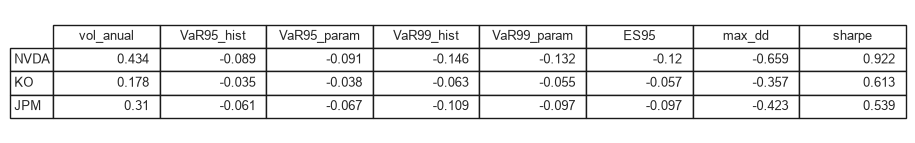

In [17]:
print("Dif. VaR99 (hist - param) mediana:", round(panel.dif_VaR99.median(), 4), "| hist más extremo en", int((panel.dif_VaR99 < 0).sum()), "de 30 | máx |dif|:", round(panel.dif_VaR99.abs().max(), 3), panel.dif_VaR99.abs().idxmax())
print("Dif. VaR95 mediana:", round(panel.dif_VaR95.median(), 4), "| hist menos extremo (dif>0) en", int((panel.dif_VaR95 > 0).sum()), "de 30")
print("ES95/VaR95 hist (mediana):", round((panel.ES95 / panel.VaR95_hist).median(), 3), "| Sharpe mediana:", round(panel.sharpe.median(), 3), "| max_dd mediano:", round(panel.max_dd.median(), 3))
cols = ["vol_anual", "VaR95_hist", "VaR95_param", "VaR99_hist", "VaR99_param", "ES95", "max_dd", "sharpe"]
tab = panel.loc[list(REP.values()), cols].round(3)
fig, ax = plt.subplots(figsize=(11, 1.6)); ax.axis("off")
tb = ax.table(cellText=tab.values, rowLabels=tab.index, colLabels=cols, loc="center"); tb.auto_set_font_size(False); tb.set_fontsize(9); tb.scale(1, 1.4)
fig.savefig(config.DIR_ASSETS / "panel_riesgo_3tickers.png", dpi=150, bbox_inches="tight"); plt.show()


**Lectura:** al 99% el VaR histórico es más extremo que el paramétrico en 30 de 30 acciones (diferencia mediana -1.31 puntos porcentuales por semana; máxima en PNC, 3.2 pp), mientras que al 95% la diferencia es pequeña (mediana +0.24 pp; el histórico es menos extremo en 26 de 30). Es el patrón de colas pesadas: la normal sobrestima el riesgo en el cuerpo y lo subestima en la cola extrema. La pérdida esperada al 95% es 1.55 veces el VaR histórico (mediana). El max drawdown mediano es -54.4% y el Sharpe mediano 0.47; los financieros concentran las mayores brechas de colas (BAC, C, USB, PNC, WFC). La tabla de los 3 representativos se exporta como figura.

## 9b. HP1 (secundaria): backtesting del VaR histórico móvil al 95%
**Justificación:** el VaR de la semana t+1 se estima con las 52 semanas hasta t (`var_historico_movil` desplazado un periodo, sin look-ahead) y se compara con el retorno realizado. Se usa la prueba de cobertura incondicional de Kupiec (LR ~ χ²₁); ignora la independencia de las excepciones (se espera agrupamiento en crisis), así que sirve para la tasa y no para la dinámica.


In [18]:
from scipy.special import xlogy
def kupiec(x, n, p=0.05):
    ph = x / n
    lr = -2 * (xlogy(n - x, 1 - p) + xlogy(x, p)) + 2 * (xlogy(n - x, 1 - ph) + xlogy(x, ph))
    return lr, stats.chi2.sf(lr, 1)
bt = {}
for t in config.tickers():
    r = R[t].dropna(); v = rg.var_historico_movil(r, 52, .05).shift(1)
    d = pd.concat([r, v], axis=1, keys=["r", "var"]).dropna()
    exc = d.r < d["var"]; x, n = int(exc.sum()), len(d); lr, p = kupiec(x, n)
    bt[t] = {"n": n, "excepciones": x, "tasa": x / n, "LR": lr, "p_kupiec": p, "x_crisis": int(exc[(exc.index.year == 2020) | (exc.index.year == 2022)].sum())}
bt = pd.DataFrame(bt).T.astype({"n": int, "excepciones": int, "tasa": float, "LR": float, "p_kupiec": float, "x_crisis": int})
print(bt.round(3).head(8).to_string())
print("Tasa de excepciones: mediana", round(bt.tasa.median(), 4), "rango", round(bt.tasa.min(), 4), "-", round(bt.tasa.max(), 4), "(esperada 0.05)")
print("Kupiec rechaza (p<0.05):", int((bt.p_kupiec < .05).sum()), "de 30 | tasa>5%:", int((bt.tasa > .05).sum()), "| tasa agregada:", round(bt.excepciones.sum() / bt.n.sum(), 4))
print("Control de la fórmula LR con x=n*0.05 -> LR:", round(kupiec(50, 1000)[0], 6))


         n  excepciones   tasa      LR  p_kupiec  x_crisis
AAPL   875           63 0.0720  7.8940    0.0050        12
MSFT   875           65 0.0740  9.5140    0.0020        12
GOOGL  875           61 0.0700  6.4110    0.0110        13
META   700           43 0.0610  1.8000    0.1800        10
NVDA   875           59 0.0670  5.0690    0.0240        10
ORCL   875           66 0.0750 10.3740    0.0010         8
ADBE   875           60 0.0690  5.7220    0.0170        12
CRM    875           64 0.0730  8.6870    0.0030        12
Tasa de excepciones: mediana 0.0674 rango 0.0583 - 0.0754 (esperada 0.05)
Kupiec rechaza (p<0.05): 20 de 30 | tasa>5%: 30 | tasa agregada: 0.0666
Control de la fórmula LR con x=n*0.05 -> LR: 0.0


In [19]:
# Backtest fuera de muestra del VaR 95% de GARCH-t (parámetros fijados con datos hasta 2019-12-31)
q_t = lambda nu: stats.t.ppf(.05, nu) * np.sqrt((nu - 2) / nu)   # cuantil de la t estandarizada (varianza 1)
bg, bh = {}, {}
for t in config.tickers():
    r = R[t].dropna() * 100; te = r.index > CORTE; p = AJ[t]
    var_g = (p["mu"] + VOLG[t] * q_t(p["nu"]))[te]          # sigma_t usa solo información hasta t-1
    x, n = int((r[te] < var_g).sum()), int(te.sum()); lr, pv = kupiec(x, n)
    bg[t] = {"n": n, "exc_garch": x, "tasa_garch": x / n, "p_kupiec_garch": pv}
    vh = rg.var_historico_movil(R[t].dropna(), 52, .05).shift(1)[R[t].dropna().index > CORTE]
    xh = int((R[t].dropna()[te] < vh).sum()); bh[t] = {"exc_hist": xh, "tasa_hist": xh / n, "p_kupiec_hist": kupiec(xh, n)[1]}
cmp_ = pd.DataFrame(bg).T.join(pd.DataFrame(bh).T).astype({"n": int, "exc_garch": int, "exc_hist": int})
print(cmp_.round(3).head(6).to_string())
for k in ["garch", "hist"]:
    print(f"VaR {k} (2020+): tasa mediana {cmp_['tasa_'+k].median():.4f} (rango {cmp_['tasa_'+k].min():.4f}-{cmp_['tasa_'+k].max():.4f}) | tasa agregada {cmp_['exc_'+k].sum()/cmp_.n.sum():.4f} | Kupiec rechaza {(cmp_['p_kupiec_'+k] < .05).sum()} de 30")
print("GARCH-t tasa<5% en", int((cmp_.tasa_garch < .05).sum()), "series | |tasa-5%| menor con GARCH que con hist en", int(((cmp_.tasa_garch - .05).abs() < (cmp_.tasa_hist - .05).abs()).sum()), "de 30")
print("Peor cobertura GARCH-t:", cmp_.tasa_garch.idxmax(), round(cmp_.tasa_garch.max(), 3), "| nu de esa serie:", round(AJ[cmp_.tasa_garch.idxmax()]["nu"], 2), "| mediana de tasa sin esa serie:", round(cmp_.tasa_garch.drop(cmp_.tasa_garch.idxmax()).median(), 4))
print("Representativos tasa GARCH / hist:", {t: (round(cmp_.loc[t, "tasa_garch"], 3), round(cmp_.loc[t, "tasa_hist"], 3)) for t in REP.values()})
print("Kupiec p>=0.05 en ambos:", int(((cmp_.p_kupiec_garch >= .05) & (cmp_.p_kupiec_hist >= .05)).sum()), "| solo hist:", int(((cmp_.p_kupiec_garch < .05) & (cmp_.p_kupiec_hist >= .05)).sum()), "| solo GARCH:", int(((cmp_.p_kupiec_garch >= .05) & (cmp_.p_kupiec_hist < .05)).sum()))


         n  exc_garch  tasa_garch  p_kupiec_garch  exc_hist  tasa_hist  p_kupiec_hist
AAPL   354         25      0.0710          0.0930        25     0.0710         0.0930
MSFT   354         31      0.0880          0.0030        31     0.0880         0.0030
GOOGL  354         31      0.0880          0.0030        28     0.0790         0.0200
META   354         28      0.0790          0.0200        24     0.0680         0.1440
NVDA   354         19      0.0540          0.7540        22     0.0620         0.3120
ORCL   354         36      0.1020          0.0000        31     0.0880         0.0030
VaR garch (2020+): tasa mediana 0.0749 (rango 0.0537-0.1582) | tasa agregada 0.0780 | Kupiec rechaza 15 de 30
VaR hist (2020+): tasa mediana 0.0678 (rango 0.0508-0.0876) | tasa agregada 0.0696 | Kupiec rechaza 8 de 30
GARCH-t tasa<5% en 0 series | |tasa-5%| menor con GARCH que con hist en 8 de 30
Peor cobertura GARCH-t: ADBE 0.158 | nu de esa serie: 5.33 | mediana de tasa sin esa serie: 0.0734
R

**Lectura (backtest fuera de muestra desde 2020, 354 semanas por acción):** el VaR 95% de GARCH-t (parámetros fijados con datos hasta 2019, cuantil de la t estandarizada) tiene una tasa de excepciones mediana de 7.49% (rango 5.37%-15.82%; agregada 7.80%) y Kupiec rechaza la cobertura en 15 de 30 series; el VaR histórico móvil de 52 semanas, en la misma ventana, tiene 6.78% mediana (agregada 6.96%) y Kupiec rechaza en 8 de 30. Ninguna serie queda por debajo del 5%. Ambos métodos subestiman el riesgo en 2020-2026, y GARCH-t no es mejor que el histórico en cobertura: solo está más cerca del 5% en 8 de 30 series. Cobertura correcta con ambos: 13 series; solo el histórico: 9; solo GARCH-t: 2. El peor caso es ADBE (15.8%, ν=5.33; solución de frontera α≈0, ver arriba); sin él la mediana de GARCH-t es 7.34%. Representativos (GARCH-t / histórico): NVDA 5.4%/6.2%, KO 7.6%/5.4%, JPM 6.5%/6.2%.

Interpretación: la ventaja de GARCH-t en QLIKE (que mide la calidad de σ, sección 5) no se traduce en mejor cobertura del VaR 95%. Posibles razones, no probadas aquí: parámetros fijos hasta 2019 con una muestra de entrenamiento corta (~570 semanas) y un único periodo fuera de muestra con choques (2020, 2022); ν estimado alto frente a colas reales; y que la prueba de Kupiec trata el exceso como independiente, cuando las excepciones se agrupan en crisis.


**Lectura:** la tasa de excepciones del VaR histórico móvil de 52 semanas al 95% tiene mediana 6.74% (rango 5.83%-7.54%; agregada 6.66%), por encima del 5% esperado en las 30 acciones; la prueba de Kupiec rechaza la cobertura correcta (p<0.05) en 20 de 30. El VaR móvil tarda en reaccionar a un aumento de volatilidad (agrupada, sección 4): las excepciones se concentran en episodios como 2020 y 2022 (cerca de 8-13 excepciones por acción en esos dos años). Esta prueba no contrasta independencia, y las excepciones agrupadas no son independientes, lo que refuerza que la cobertura por ventana fija se asocia con subestimación del riesgo en regímenes cambiantes.

**Síntesis (secciones 3, 5, 9 y 9b, HP1): parcialmente apoyada.**
- Apoya la primera mitad (el GBM normal subestima las colas): ν<10 en 34 de 34, VaR 99% histórico más extremo que el normal en 30 de 30 y GARCH-t mejor que el GBM en volatilidad (QLIKE, 28 de 34).
- No apoya la segunda mitad en términos de cobertura del VaR: fuera de muestra (2020+), el VaR 95% de GARCH-t tiene 7.49% de excepciones (mediana; Kupiec rechaza en 15 de 30) y el histórico móvil 6.78% (rechaza en 8 de 30); sobre toda la muestra el histórico tiene 6.74% (rechaza en 20 de 30). Ninguno alcanza el 5%.
- Decisión: GARCH-t/EWMA para σ en la simulación (mejor QLIKE), pero el riesgo reportado no se presenta como bien calibrado: se acompaña del VaR 99% histórico y se advierte la subestimación en regímenes de crisis.


## 10. Síntesis general

| Hipótesis | Estado | Cifras clave | Decisión que alimenta |
|---|---|---|---|
| HP0 (colas pesadas y volatilidad agrupada) | **Apoyada** | curtosis exceso mediana 4.63; ν mediano 4.15; LB(r²) 88.2% y ARCH-LM 85.3% significativos; GARCH-t mejor que GBM en 28 de 34 (QLIKE 3.713 vs. 3.883) | Simulación con volatilidad condicional e innovaciones t (no GBM normal) |
| HT0 (caminata aleatoria como línea base) | **Apoyada, con dependencia lineal pequeña** | ADF no rechaza en 33 de 34 log-precios y rechaza en 34 de 34 retornos; indicadores estacionarios en 208 de 210 pares; LB(r) 50% pero 11.8% con residuos GARCH-t y |ρ₁| mediana 0.068 | La caminata aleatoria es la línea base del SVM; se usan retornos e indicadores, no niveles |
| HF1 (múltiplos revierten a su historia) | **No apoyada** (25 tickers con datos consistentes; NVDA, AAPL, WMT, KHC y GOOGL no concluyentes) | 4 de 29 revierten (4 de 25 sin los afectados por splits) (ADF y η finito); vida media 0.43-0.58 años en esos 4 (META dudosa) y 1.31 años mediana general | Percentil del múltiplo solo como variable de contexto, con cambios de régimen como limitación |
| HT4 (la volatilidad se agrupa) | **Apoyada** | ARCH-LM 85.3%; persistencia mediana 0.943 | Barreras escaladas con σ |
| HP1 (GBM normal subestima colas; GARCH-t describe mejor el riesgo) | **Parcialmente apoyada** | colas: ν<10 en 34 de 34, VaR99 hist. más extremo en 30 de 30, QLIKE 28 de 34; cobertura VaR95 fuera de muestra: GARCH-t 7.49% (Kupiec rechaza 15 de 30), histórico 6.78% (8 de 30) | GARCH-t/EWMA para σ; riesgo reportado con VaR 99% histórico y advertencia de subestimación |

**Limitaciones generales.** EPS de EDGAR sin ajustar por splits (deuda de datos, sección 8); Pruebas con supuestos i.i.d. aplicadas a series dependientes (se usan de forma descriptiva); un único periodo fuera de muestra para GARCH (con el choque de 2020); KPSS con p truncado; GOOGL sin P/E; META (desde 2012) y KHC (desde 2015) con menor historia. Todos los resultados describen asociaciones, no causas.
